# Solar filament segmentation: the submitted pipeline

This notebook goes from raw GONG H-alpha images to the submitted CSV. It needs nothing beyond this repository and the
competition's images: the checkpoint is downloaded from the repository's GitHub release. Built with DINOv3.

The method is one Mask R-CNN with a ConvNeXt-T backbone (DINOv3 weights), trained on all 707 training images, applied
to 8 views of each image.

| Section | What it does | Time |
|---|---|---|
| 1. Setup | finds or clones the repository | 1 min (5 with `INSTALL`) |
| 2. Data | the images, the annotations, why several annotators matter | 1 min |
| 3. Validation | folds and the official metric | instant |
| 4. Training | the model config and the training command | off by default, ~5 h on a Kaggle T4 |
| 5. Weights | downloads and hash-checks the checkpoint | 1 min |
| 6. One image | every stage of the pipeline on one test image | 1 min |
| 7. Test set | writes the submission CSV | ~7 min on a GPU |
| 8. Check | compares the result with the file submitted to Kaggle | 1 min |
| 9. Results | the held-out scores and timing | instant |

**Environment:** Python 3.12 with `requirements.txt`, on a GPU with at least 2 GiB. On Kaggle, attach the competition
data, enable a GPU and set `INSTALL = True`. Elsewhere, set `FILAMENT_DATA` to the `MAGFiLO_1.0_Kaggle_2026` folder, or
extract the data into `filament-segmentation-2026/` in the repo root.

## 1. Setup

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/LucaT2/solar-filament-segmentation.git"
INSTALL = False        # True: install the pinned requirements (restart the kernel afterwards if torch changed)
RUN_TRAINING = False   # True: retrain the model (~5 h on a Kaggle T4) instead of downloading it
RUN_TEST_SET = True    # False: skip section 7 if its CSV does not exist yet

root = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/filament/final.py").exists()), None)
if root is None:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL], check=True)
    root = Path.cwd() / "solar-filament-segmentation"
if INSTALL:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")], check=True)
sys.path.insert(0, str(root / "src"))


def run(script, *args):
    """Run a repository script, with the library on its path."""
    env = {**os.environ, "PYTHONPATH": str(root / "src")}
    subprocess.run([sys.executable, "-W", "ignore", str(root / script), *map(str, args)], check=True, cwd=root, env=env)


import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml

from filament.data.annotations import annotation_table, load_coco
from filament.data.folds import load_folds
from filament.data.images import read_image
from filament.data.rle import rle_to_mask
from filament.data.submission import read_submission, validate_submission
from filament.detection.dataset import full_image_input
from filament.detection.instances import to_prob_map
from filament.detection.model import predict_instances
from filament.evaluation.metric import pq_score
from filament.final import FINAL_CONFIG_DIR, VIEWS, FinalPipeline
from filament.paths import get_data_paths, get_output_dir
from filament.postprocess.pipeline import load_postprocess
from filament.segmentation.dataset import image_info

paths = get_data_paths()
print("repo:", root)
print("data:", paths.root)
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU (slow)")

C:\Users\lucat\Kaggle_Competitions\Solar_Filament\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


repo: C:\Users\lucat\Kaggle_Competitions\Solar_Filament
data: C:\Users\lucat\Kaggle_Competitions\Solar_Filament\filament-segmentation-2026\MAGFiLO_1.0_Kaggle_2026
device: NVIDIA GeForce RTX 5070 Laptop GPU


## 2. Data

707 training and 180 test images of 2048×2048 pixels from the six GONG sites. Each annotation is one filament.

296 training images were annotated by two or three people independently, and the official metric scores each
annotator's version separately against the same prediction. Annotators often disagree on outlines and on whether a
filament is one object or several, so the score has a ceiling well below 1: **one annotator scored against the others
gets PQ 0.34**.

8199 filaments on 707 images; 296 images have several annotators


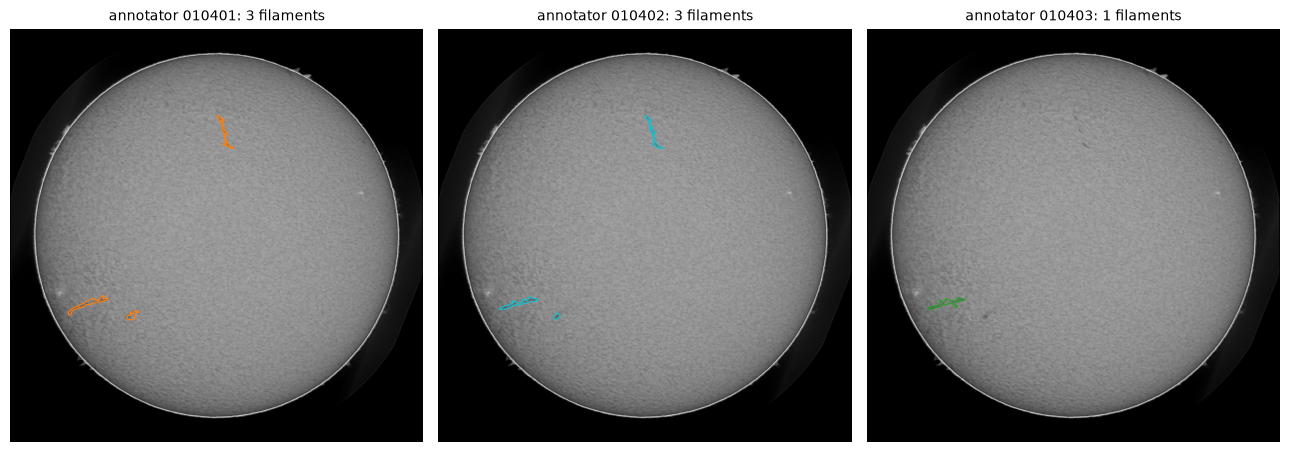

In [2]:
ann = annotation_table(load_coco(paths.annotations))
per_stem = ann.groupby("stem").annotator_image.nunique()
print(f"{len(ann)} filaments on {ann.stem.nunique()} images; {(per_stem > 1).sum()} images have several annotators")


def outline(ax, mask, color):
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    for c in contours:
        ax.plot(*np.append(c[:, 0], c[:1, 0], axis=0).T, color=color, lw=0.8)


stem = per_stem[per_stem == 3].index[0]
img = read_image(paths.train_images / f"{stem}.jpeg")
versions = list(ann[ann.stem == stem].groupby("annotator_image"))
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, (name, rows), color in zip(axes, versions, ("tab:orange", "tab:cyan", "tab:green")):
    ax.imshow(img, cmap="gray")
    for r in rows.rle:
        outline(ax, rle_to_mask(r), color)
    ax.set_title(f"annotator {name.split('-')[0]}: {len(rows)} filaments", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Validation

The folds are grouped by image, so the same image never appears in training and validation under different
annotators, and stratified by site and number of annotators. Every model and setting was chosen on held-out
predictions, scored with a reimplementation of the official metric that the tests check against the organizers' code.
Two models are compared on the same images with a paired bootstrap, which resolves differences of about 0.01 PQ on one
fold. The public leaderboard shows 2 decimals on about 90 images, so it cannot.

The final model trains on all images, so it has no held-out score of its own. Its architecture, its schedule and its
post-processing settings were all chosen with a model trained on folds 1–4 and scored on fold 0.

In [3]:
folds = load_folds()
print(folds.groupby("fold").size().rename("images").to_frame().T.to_string())

fold      0    1    2    3    4
images  142  142  141  141  141


## 4. Training

The backbone starts from Meta's DINOv3 ConvNeXt-T weights (timm `convnext_tiny.dinov3_lvd1689m`), the RPN and box and
mask heads from COCO Mask R-CNN weights. Only the FPN's input convolutions start from scratch. All backbone layers are
trained, at a quarter of the learning rate.

In [4]:
CONFIG = "configs/detection/maskrcnn/maskrcnn_dinov3_convnext_t_m56.yaml"
OVERRIDES = {"epochs": 29, "fit_epochs": False, "max_hours": 6.5}   # as the submitted run: fixed schedule, seed 42

config = {**yaml.safe_load((root / CONFIG).read_text()), **OVERRIDES}
KEYS = ["backbone", "pretrained", "trainable_layers", "backbone_lr_mult", "mask_size", "crop", "batch_size", "epochs",
        "samples_per_epoch", "lr", "weight_decay", "warmup_epochs", "augment", "seed"]
print(pd.Series({k: config[k] for k in KEYS}).to_string())

command = ("scripts/detection/train.py", "--config", CONFIG, "--fold", -1, "--set",
           *(f"{k}={str(v).lower()}" for k, v in OVERRIDES.items()))
print("\npython", *command)
if RUN_TRAINING:
    run(*command)

backbone             convnext_tiny.dinov3_lvd1689m
pretrained                                    True
trainable_layers                                 5
backbone_lr_mult                              0.25
mask_size                                       56
crop                                          1024
batch_size                                       4
epochs                                          29
samples_per_epoch                             2000
lr                                          0.0001
weight_decay                                0.0001
warmup_epochs                                    2
augment                                       base
seed                                            42

python scripts/detection/train.py --config configs/detection/maskrcnn/maskrcnn_dinov3_convnext_t_m56.yaml --fold -1 --set epochs=29 fit_epochs=false max_hours=6.5


`--fold -1` trains on all images and saves `full_s42.pt` at the last epoch. The settings below were tuned on
fold 0 with `scripts/postprocess/tune_postprocess.py`; the README lists the commands.

In [5]:
cfg = load_postprocess(FINAL_CONFIG_DIR / "postprocess.json")
print(cfg)

PostConfig(threshold=0.45, min_area=0, min_score=0.8, disk_scale=1.0, link_px=0)


## 5. Download the checkpoint

In [6]:
if not RUN_TRAINING:
    run("scripts/final/download_weights.py")

## 6. One image, stage by stage

Detections are merged across 8 views, and a filament's score is the sum of its scores divided by the number of views,
so a filament seen in only a few views scores low. Each soft mask is then pasted at the mask threshold, highest score
first, so instances never overlap. Finally, instances under the score cut-off are dropped.

92 detections in one view, 175 after merging 8 views, 51 instances on the disk, 16 above the score cut-off


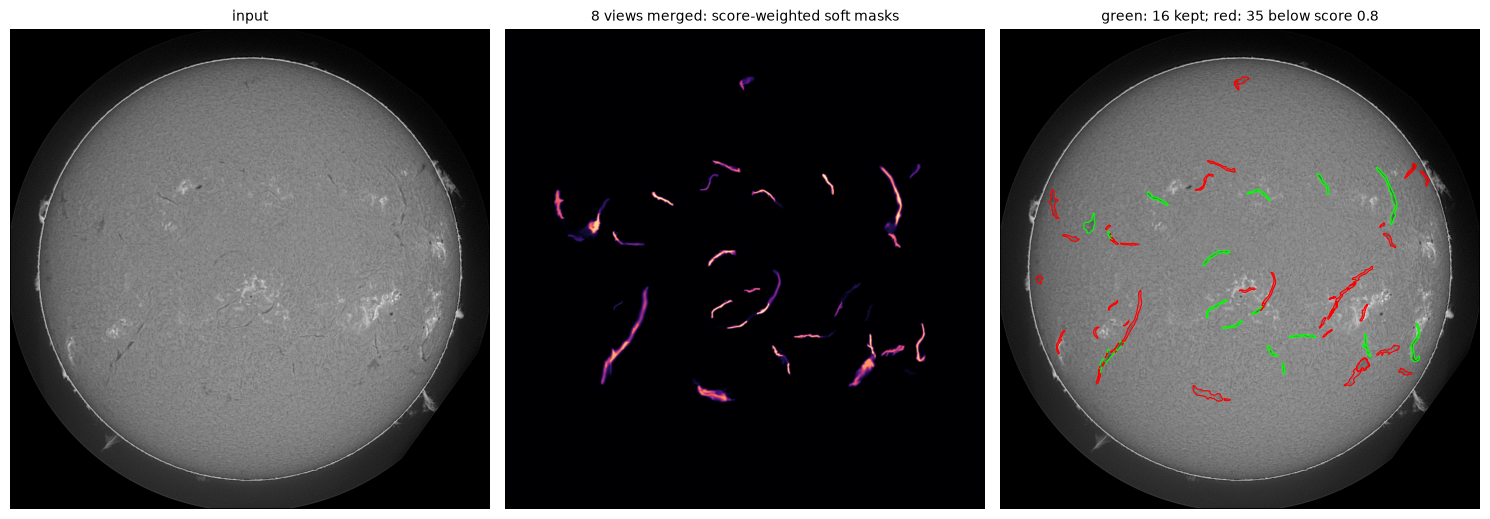

In [7]:
pipeline = FinalPipeline.load()
path = paths.test_images / "20140420195854Bh.jpeg"
info = image_info(path)
img = read_image(path)

one_view = predict_instances(pipeline.model, full_image_input(info), pipeline.device, torch.float16)
detections = pipeline.detect(path, info)
comps = pipeline.components(detections, info)
keep = set(comps.keep(cfg.min_area, cfg.min_score).tolist())
print(f"{len(one_view)} detections in one view, {len(detections)} after merging {VIEWS} views, "
      f"{comps.n} instances on the disk, {len(keep)} above the score cut-off")

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4))
axes[0].imshow(img, cmap="gray")
axes[0].set_title("input", fontsize=10)
axes[1].imshow(to_prob_map(detections), cmap="magma", vmin=0, vmax=1)
axes[1].set_title(f"{VIEWS} views merged: score-weighted soft masks", fontsize=10)
axes[2].imshow(img, cmap="gray")
for i in range(1, comps.n + 1):
    outline(axes[2], comps.labels == i, "lime" if i in keep else "red")
axes[2].set_title(f"green: {len(keep)} kept; red: {comps.n - len(keep)} below score {cfg.min_score}", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [8]:
pd.DataFrame({"score": comps.mean_prob[1:], "area_px": comps.area[1:],
              "kept": [i in keep for i in range(1, comps.n + 1)]}).sort_values("score", ascending=False).round(3)

,score,area_px,kept
0,0.994,994,True
1,0.990,632,True
2,0.988,881,True
3,0.986,960,True
4,0.982,1386,True
5,0.963,2909,True
6,0.945,888,True
7,0.945,829,True
8,0.935,642,True
9,0.916,345,True


## 7. The test set

In [9]:
del pipeline
torch.cuda.empty_cache()
regenerated = get_output_dir() / "submission_regenerated.csv"
if RUN_TEST_SET and not regenerated.exists():
    run("scripts/final/predict.py", "--out", regenerated)
df = read_submission(regenerated)
print(f"{len(df)} filaments, {len(df) / 180:.2f} per image; validation problems: {validate_submission(df)}")

1308 filaments, 7.27 per image; validation problems: []


## 8. Does it match what was submitted?

`submissions/submission_mrcnn_dino_full_s42.csv` is the file Kaggle scored (public LB 0.39). On the machine that
produced it, the regenerated file is byte-identical. A different GPU can change a few pixels through floating-point
rounding, so the agreement is also given as PQ with the submitted file standing in for the ground truth.

In [10]:
submitted = read_submission(root / "submissions/submission_mrcnn_dino_full_s42.csv")
same = len(set(submitted.segmentation_rle) & set(df.segmentation_rle))
reference = submitted.assign(filament_id="x-" + submitted.filament_id)
agreement = pq_score(reference, df)
print(f"submitted {len(submitted)} filaments, regenerated {len(df)}, identical masks {same}")
print(f"agreement: PQ {agreement.pq:.4f}, SQ {agreement.sq:.4f}, RQ {agreement.rq:.4f}")

submitted 1308 filaments, regenerated 1308, identical masks 1308
agreement: PQ 1.0000, SQ 1.0000, RQ 1.0000


## 9. Results

The fold-0 model (same recipe, trained on folds 1–4) on the 142 images of fold 0, from
`scripts/evaluation/rubric_metrics.py`. The final model trained on 25% more images, which cannot be measured here.
The human reference is on all multi-annotated images.

In [11]:
model = pd.read_csv(root / "notes/results/dino_fold0/summary.csv").set_index("experiment")
human = pd.read_csv(root / "notes/results/rubric_summary.csv").set_index("experiment").loc[["human"]]
columns = {"pq": "PQ", "sq": "SQ", "rq": "RQ", "precision": "precision", "recall": "recall",
           "overlap_median_dice": "median pair Dice", "pixel_dice_median": "median pixel Dice",
           "gt_missed": "GT missed", "gt_split_1ton": "1:n splits", "pred_merge_nto1": "n:1 merges"}
table = pd.concat([model, human]).rename(index={"mrcnn_dino_f0_tta8": "fold-0 model", "human": "human agreement"})
table[list(columns)].rename(columns=columns).round(3).T

experiment,fold-0 model,human agreement
PQ,0.452,0.340
SQ,0.685,0.633
RQ,0.660,0.537
precision,0.675,0.535
recall,0.646,0.539
median pair Dice,0.790,0.718
median pixel Dice,0.686,0.643
GT missed,0.194,0.176
1:n splits,0.039,0.032
n:1 merges,0.029,0.030


In [12]:
timing = pd.read_csv(root / "notes/results/inference_timing.csv")
timing[["pipeline", "device", "total_s_per_image", "test_set_min", "peak_gpu_gib"]].round(2)

,pipeline,device,total_s_per_image,test_set_min,peak_gpu_gib
0,dino_full_tta8,NVIDIA GeForce RTX 5070 Laptop GPU,2.32,6.97,1.45
1,detector_1model,NVIDIA GeForce RTX 5070 Laptop GPU,0.45,1.34,1.73
2,detector_5f_tta8,NVIDIA GeForce RTX 5070 Laptop GPU,15.83,47.49,2.43
3,unet_1model,NVIDIA GeForce RTX 5070 Laptop GPU,0.68,2.04,1.71
4,w40_classifier,NVIDIA GeForce RTX 5070 Laptop GPU,25.67,77.01,3.57
